# 03. Results across all drugs

Nested 5-fold cross-validation for every drug screened in at least 300 GDSC2 cell lines. The outer
folds are the same for every drug and model (each line assigned once, stratified by tissue), so
model comparisons are paired.

In [1]:
import sys, warnings, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
T = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
from drugresponse import data

In [2]:
summ = pd.read_csv(T / "summary.csv", index_col=0)
summ.round(3)

,n_drugs,median_r,median_r2,median_rho_within,share_r_above_0_3,median_gain_vs_tissue,share_beats_tissue,wilcoxon_p_vs_tissue
model,,,,,,,,
Mean,281,-0.058,-0.002,NaN,0.000,-0.319,0.004,0.0
Tissue,281,0.261,0.055,NaN,0.434,NaN,NaN,NaN
PCR,281,0.364,0.128,0.156,0.598,0.090,0.893,0.0
Ridge,281,0.402,0.161,0.194,0.665,0.116,0.975,0.0
Lasso,281,0.382,0.142,0.151,0.612,0.087,0.883,0.0
Elastic net,281,0.382,0.144,0.155,0.612,0.088,0.883,0.0


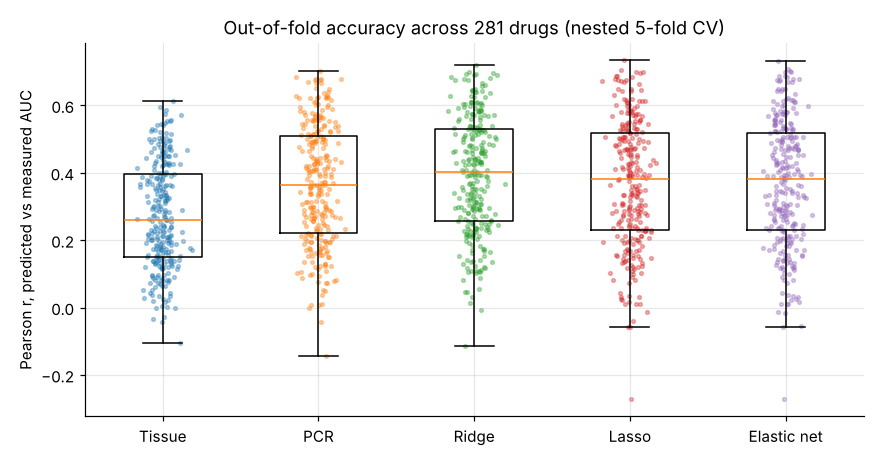

In [3]:
display(Image(FIG / 'accuracy_by_model.png'))

**How to read it.** `median_r` is the median across drugs of the correlation between out-of-fold
predicted and measured AUC. `median_rho_within` is the median within-tissue Spearman correlation:
how well the model ranks lines inside the same cancer type, which tissue alone cannot do.
`share_beats_tissue` is the share of drugs on which the model's r beats the tissue-only model.
The Wilcoxon p-value tests the paired per-drug differences (drugs are not independent: several share
targets, so treat it as descriptive).

In [4]:
pw = pd.read_csv(T / "pairwise_wins.csv", index_col=0)
print("share of drugs on which the row model has higher r than the column model")
pw.round(2)

share of drugs on which the row model has higher r than the column model


,Tissue,PCR,Ridge,Lasso,Elastic net
Tissue,0.00,0.11,0.02,0.12,0.12
PCR,0.89,0.00,0.06,0.53,0.51
Ridge,0.98,0.94,0.00,0.85,0.85
Lasso,0.88,0.47,0.15,0.00,0.25
Elastic net,0.88,0.49,0.15,0.75,0.00


In [5]:
pd.read_csv(T / "best_model_counts.csv", index_col=0)

,n_drugs_best
Ridge,220
Elastic net,23
Lasso,18
PCR,15
Tissue,5


## Where does expression add to cancer type?

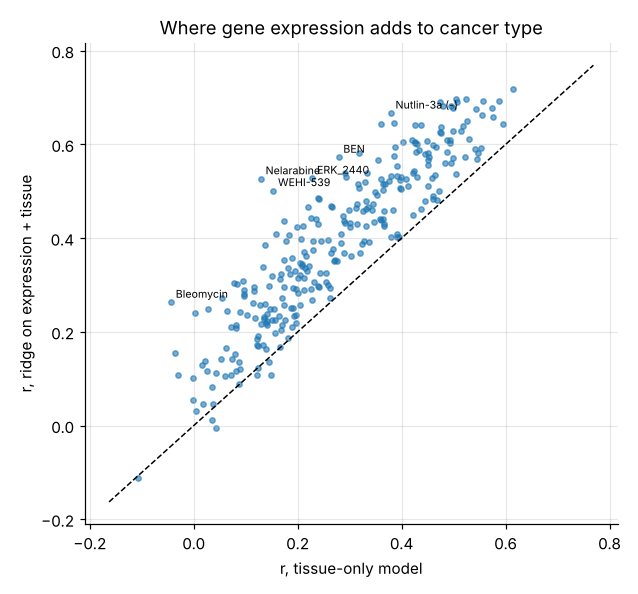

In [6]:
display(Image(FIG / 'ridge_vs_tissue.png'))

In [7]:
per = pd.read_csv(T / "per_drug_ridge.csv", dtype={"drug": str})
cols = ["drug_name", "target", "n", "r_tissue", "r", "r_elastic_net", "gain_vs_tissue", "rho_within"]
print("Most predictable drugs (ridge)"); display(per[cols].head(12).round(3))
print("Largest gain over tissue"); display(per.sort_values("gain_vs_tissue", ascending=False)[cols].head(10).round(3))
print("Least predictable"); display(per[cols].tail(8).round(3))

Most predictable drugs (ridge)


,drug_name,target,n,r_tissue,r,r_elastic_net,gain_vs_tissue,rho_within
0,Schweinfurthin A,NaN,697,0.614,0.719,0.698,0.105,0.340
1,Cytarabine,Antimetabolite,726,0.524,0.698,0.702,0.174,0.387
2,Camptothecin,TOP1,943,0.504,0.696,0.732,0.192,0.504
3,Vorinostat,"HDAC inhibitor Class I, IIa, IIb, IV",934,0.586,0.693,0.679,0.106,0.343
4,BI-2536,"PLK1, PLK2, PLK3",899,0.556,0.693,0.678,0.137,0.402
5,AZD5991,MCL1,694,0.506,0.691,0.669,0.185,0.352
6,ABT737,"BCL2, BCL-XL, BCL-W, BCL-B, BFL1",932,0.473,0.690,0.686,0.217,0.370
7,Irinotecan,TOP1,940,0.496,0.683,0.700,0.187,0.456
8,Trametinib,"MEK1, MEK2",941,0.480,0.682,0.674,0.202,0.540
9,PD0325901,"MEK1, MEK2",943,0.500,0.679,0.670,0.179,0.508


Largest gain over tissue


,drug_name,target,n,r_tissue,r,r_elastic_net,gain_vs_tissue,rho_within
76,Nelarabine,NaN,697,0.129,0.527,0.496,0.397,0.187
89,WEHI-539,BCL-XL,937,0.153,0.501,0.506,0.348,0.288
207,Bleomycin,dsDNA break induction,698,-0.044,0.263,0.170,0.307,0.212
72,ERK_2440,"ERK1,ERK2",698,0.228,0.528,0.475,0.300,0.354
51,BEN,NaN,698,0.279,0.573,0.614,0.294,0.432
12,Nutlin-3a (-),MDM2,943,0.379,0.667,0.687,0.287,0.439
18,Acetalax,NaN,698,0.360,0.643,0.605,0.283,0.268
46,Selumetinib,"MEK1, MEK2",698,0.318,0.582,0.576,0.264,0.401
121,Uprosertib,"AKT1, AKT2, AKT3",875,0.174,0.438,0.432,0.263,0.251
16,Acetalax,NaN,698,0.386,0.647,0.615,0.261,0.252


Least predictable


,drug_name,target,n,r_tissue,r,r_elastic_net,gain_vs_tissue,rho_within
273,EPZ004777,DOT1L,940,0.035,0.082,-0.014,0.046,0.047
274,Motesanib,"VEGFR, RET, KIT, PDGFR",925,-0.002,0.056,-0.017,0.058,0.014
275,LMB_AB1,"ADRA1A, ADRB1",698,0.037,0.047,-0.057,0.010,-0.043
276,IRAK4_4710,IRAK4,698,0.018,0.046,0.042,0.028,0.037
277,EPZ5676,DOT1L,937,0.005,0.030,0.010,0.025,0.112
278,GSK3337463A,NIK,698,0.035,0.013,-0.054,-0.022,-0.059
279,A-366,"EHMT1, EHMT2",724,0.043,-0.006,0.021,-0.048,-0.030
280,BIBR-1532,TERT,927,-0.107,-0.113,-0.272,-0.006,-0.019


## By target pathway

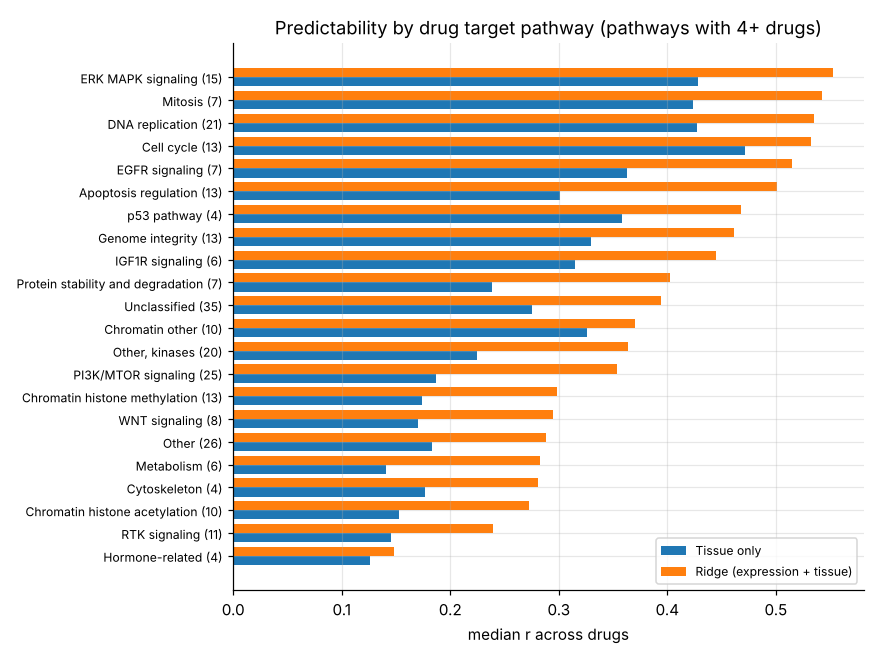

,n_drugs,median_r_ridge,median_r_tissue,median_gain,median_rho_within
pathway,,,,,
ERK MAPK signaling,15,0.553,0.429,0.172,0.386
Mitosis,7,0.543,0.423,0.121,0.307
DNA replication,21,0.535,0.427,0.132,0.265
Cell cycle,13,0.532,0.471,0.082,0.288
EGFR signaling,7,0.515,0.363,0.152,0.258
Apoptosis regulation,13,0.501,0.301,0.185,0.243
p53 pathway,4,0.468,0.358,0.091,0.137
Genome integrity,13,0.462,0.330,0.132,0.151
IGF1R signaling,6,0.445,0.315,0.118,0.225


In [8]:
display(Image(FIG / 'by_pathway.png'))
pd.read_csv(T / 'by_pathway.csv', index_col=0).round(3)